In [17]:
from astropy.io import fits
from astropy.table import Table
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [14]:
with fits.open('20260622_SUN_VINCENT.fits') as hdul:
    # Let Astropy handle the conversion to an Astro Table object,
    # which takes care of the internal byte-order formatting
    astro_table = Table(hdul[1].data)
    
    # Convert safely straight to a Pandas DataFrame
    data = astro_table.to_pandas()

print(data.columns)

Index(['JD', 'Azimuth', 'Elevation', 'Az_Offset', 'El_Offset', 'Gal_Long',
       'Gal_Lat', 'LEFT_POL', 'RIGHT_POL', 'LEFT_FILT', 'RIGHT_FILT', 'BBC02u',
       'BBC03u', 'BBC04u', 'BBC05u', 'BBC06u', 'BBC10u', 'BBC11u', 'BBC12u',
       'BBC13u', 'BBC14u', 'CAL', 'MARKER'],
      dtype='str')


In [11]:
data

,JD,Azimuth,Elevation,Az_Offset,El_Offset,Gal_Long,Gal_Lat,LEFT_POL,RIGHT_POL,LEFT_FILT,...,BBC04u,BBC05u,BBC06u,BBC10u,BBC11u,BBC12u,BBC13u,BBC14u,CAL,MARKER
0,2.461214e+06,277.5,68.1,0.0,0.0,176.817601,-13.958969,20,42,23,...,24,20,16,60,56,50,42,32,OFF,TPI 000
1,2.461214e+06,277.5,68.1,0.0,0.0,176.817601,-13.958969,20,42,23,...,24,20,16,59,56,50,42,32,OFF,TPI 001
2,2.461214e+06,277.5,68.1,0.0,0.0,176.820068,-13.955975,20,42,23,...,24,20,16,59,56,49,42,32,OFF,TPI 002
3,2.461214e+06,277.5,68.1,0.0,0.0,176.820068,-13.955975,20,42,23,...,24,20,16,60,56,50,42,32,OFF,TPI 003
4,2.461214e+06,277.5,68.1,0.0,0.0,176.822535,-13.952981,20,42,23,...,24,20,16,60,56,50,42,32,OFF,TPI 004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21997,2.461214e+06,277.5,68.1,0.0,0.0,195.026330,17.174946,21,42,24,...,25,20,16,60,55,49,42,32,OFF,TPI 21997
21998,2.461214e+06,277.5,68.1,0.0,0.0,195.026330,17.174946,21,42,24,...,25,20,16,60,56,50,43,32,OFF,TPI 21998
21999,2.461214e+06,277.5,68.1,0.0,0.0,195.027899,17.178474,21,42,24,...,25,20,16,60,55,49,42,32,OFF,TPI 21999
22000,2.461214e+06,277.5,68.1,0.0,0.0,195.027899,17.178474,21,42,24,...,25,20,16,60,55,49,43,32,OFF,TPI 22000


In [29]:
print(data['JD'][0])

2461213.6944247456


In [ ]:
delta_t_days = data['JD']-data['JD'][0]

delta_t_hours = delta_t_days*24

delta_t_min = delta_t_hours*60

delta_t_sec = delta_t_min*60

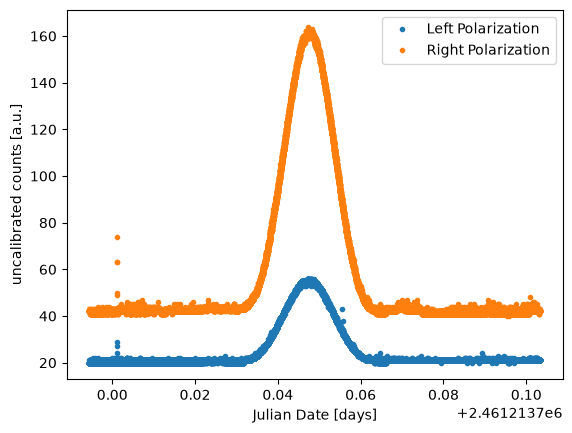

In [27]:


plt.plot(data['JD'],data['LEFT_POL'],".",label="Left Polarization")
plt.plot(data['JD'],data['RIGHT_POL'],".",label="Right Polarization")
plt.ylabel('uncalibrated counts [a.u.]')
plt.xlabel('Julian Date [days]')
plt.legend()
plt.show()

In [ ]:
np.average(data['RIGHT_POL'][data[J]])

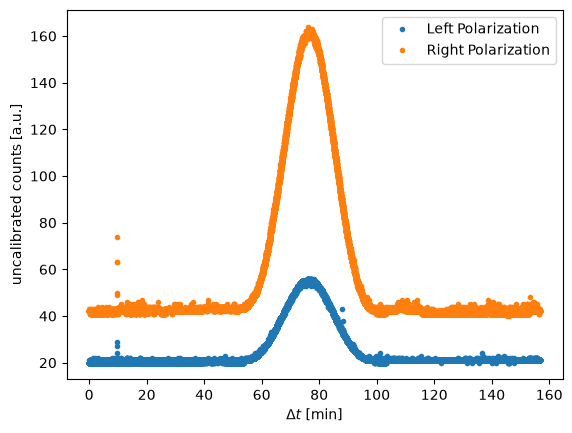

In [37]:
plt.plot(delta_t_min,data['LEFT_POL'],".",label="Left Polarization")
plt.plot(delta_t_min,data['RIGHT_POL'],".",label="Right Polarization")
plt.ylabel('uncalibrated counts [a.u.]')
plt.xlabel(r'$\Delta t$ [min]')
plt.legend()
plt.show()

In [48]:
average_right = np.average(data['RIGHT_POL'][((delta_t_min<50)|(delta_t_min>110))])
average_left = np.average(data['LEFT_POL'][((delta_t_min<50)|(delta_t_min>110))])

In [49]:
print(average_right,average_left)

42.17925915037483 20.746288402175512


In [51]:
np.max(data['RIGHT_POL']),np.max(data['LEFT_POL'])

(np.int32(164), np.int32(56))

In [57]:
HM_RIGHT = (np.max(data['RIGHT_POL']) - average_right)/2 + average_right
HM_LEFT = (np.max(data['LEFT_POL']) - average_left)/2 + average_left

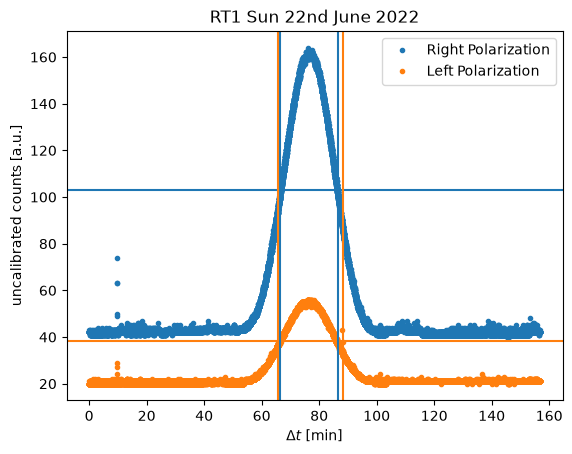

In [95]:
plt.plot(delta_t_min,data['RIGHT_POL'],".",label="Right Polarization")
plt.plot(delta_t_min,data['LEFT_POL'],".",label="Left Polarization")
plt.axhline(HM_RIGHT,c='C0')
plt.axhline(HM_LEFT,c='C1')

r1_min = np.array(delta_t_min[((data['RIGHT_POL']>HM_RIGHT-1)&(data['RIGHT_POL']<HM_RIGHT+1))])[0]
plt.axvline(r1_min,c='C0')
r2_min = np.array(delta_t_min[((data['RIGHT_POL']>HM_RIGHT-1)&(data['RIGHT_POL']<HM_RIGHT+1))])[-1]
plt.axvline(r2_min,c='C0')


l1_min = np.array(delta_t_min[((data['LEFT_POL']>HM_LEFT-1)&(data['LEFT_POL']<HM_LEFT+1))])[0]
plt.axvline(l1_min,c="C1")
l2_min = np.array(delta_t_min[((data['LEFT_POL']>HM_LEFT-1)&(data['LEFT_POL']<HM_LEFT+1))])[-1]
plt.axvline(l2_min,c='C1')


plt.ylabel('uncalibrated counts [a.u.]')
plt.xlabel(r'$\Delta t$ [min]')
plt.legend()

plt.title('RT1 Sun 22nd June 2022')
plt.show()

## Avarage velocity of the Sun = 0.25 degrees per minute
## Velocity at 2pm on 22nd June 2026 = 0.229 degrees per minute
## Declination of the Sun $+23.44^\circ$ on 22nd June 2026

In [90]:
(r2_min-r1_min)*0.229

np.float64(4.562802170589566)

In [89]:
(l2_min-l1_min)*0.229

np.float64(5.125569727644325)

In [96]:
fwhm_time_minutes_right = (r2_min-r1_min)
fwhm_time_minutes_left = (l2_min-l1_min)

In [92]:
(5.12+4.56)/2

4.84

In [93]:
(4.562802170589566+5.125569727644325)/2

4.8441859491169454

# Drift formula for the Sun

In [98]:
declination_rad = np.radians(23.44)
# drift formula for the sun
fwhm_degrees_right = fwhm_time_minutes_right * 0.25 * np.cos(declination_rad)
fwhm_degrees_left = fwhm_time_minutes_left * 0.25 * np.cos(declination_rad)

In [99]:
print('Beam angle right pol: ',fwhm_degrees_right )
print('Beam angle left pol: ',fwhm_degrees_left )

Beam angle right pol:  4.570160140004674
Beam angle left pol:  5.1338352153602065


I should renmove the size of the sun in quadrature: $$\text{HPBW}_{\text{telescope}} = \sqrt{(\text{FWHM}_{\text{measured}})^2 - (\text{Dia}_{\text{Sun}})^2}$$ and the diameter of the sun is 0.53 degrees 